# Notación y Forward Propagation

El Lab 01 presentó las piezas con palabras; aquí se aprende a leerlas y operarlas en símbolos. Al terminar: leer cualquier $a_j^{[l]}$, calcular una activación a mano y escribir la pasada completa en forma vectorizada.

### Cómo leer la notación (guía visual)

![Notación de la red](../Resources/nn_notation.png)

Cada símbolo tiene dos coordenadas:

- **Superíndice $[l]$: la capa.** $a^{[2]}$ vive en la capa 2. La entrada se escribe $a^{[0]} = x$ para que la regla sea uniforme desde la primera capa.
- **Subíndice $j$: la neurona dentro de la capa.** $a_2^{[3]}$ es la activación de la segunda neurona de la capa 3.
- **Pesos y sesgo por neurona:** la neurona $j$ de la capa $l$ tiene su propio vector $w_j^{[l]}$ y su propio escalar $b_j^{[l]}$. Distintas neuronas, distintos parámetros.

Y la regla universal, válida para cualquier $l$ y cualquier $j$:

$$a_j^{[l]} = g(w_j^{[l]} \cdot a^{[l-1]} + b_j^{[l]})$$

En palabras: la activación de una neurona es la sigmoide del puntaje formado con la salida completa de la capa anterior. Es la misma fórmula del Lab 01, escrita para decir *dónde* vive cada cosa.

### Ejemplo calculado a mano: la capa 2 completa

Una capa 2 con 2 neuronas recibe $a^{[1]} = [0.5, 0.8]$. Sus parámetros son $w_1^{[2]} = [0.6, -0.2]$, $b_1^{[2]} = 0.1$ y $w_2^{[2]} = [-0.3, 0.9]$, $b_2^{[2]} = -0.2$.

**Unidad 1:** $z = 0.5 \cdot 0.6 + 0.8 \cdot (-0.2) + 0.1 = 0.3 - 0.16 + 0.1 = 0.24$. Luego $a_1^{[2]} = g(0.24) \approx 0.56$.

**Unidad 2:** $z = 0.5 \cdot (-0.3) + 0.8 \cdot 0.9 - 0.2 = -0.15 + 0.72 - 0.2 = 0.37$. Luego $a_2^{[2]} = g(0.37) \approx 0.59$.

La salida de la capa es el vector $a^{[2]} = [0.56, 0.59]$: dos números que resumen lo que la capa detectó. Nótese el signo negativo en $w_1$: esa entrada vota *en contra* de encender la neurona 1.

a^[2] = [0.56 0.59] (igual que a mano: [0.56, 0.59])


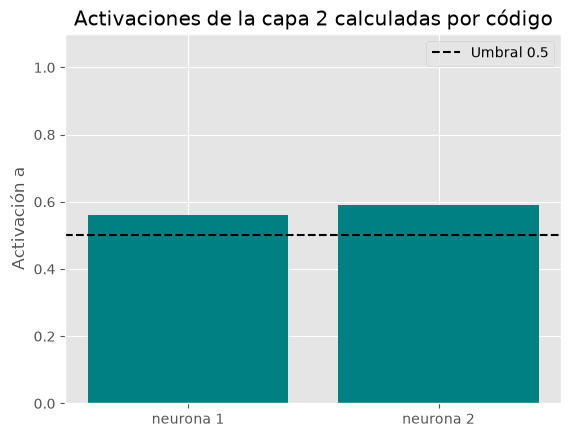

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Estilo para las gráficas
plt.style.use('ggplot')

def sigmoid(z):
    """Calcula la función sigmoide g(z) = 1 / (1 + e^(-z))."""
    return 1 / (1 + np.exp(-z))

# Paso 1: La misma capa 2 del ejemplo, ahora con matrices
a1 = np.array([0.5, 0.8])
W2 = np.array([[0.6, -0.2], [-0.3, 0.9]])
b2 = np.array([0.1, -0.2])
a2 = sigmoid(np.dot(W2, a1) + b2)
print(f"a^[2] = {np.round(a2, 2)} (igual que a mano: [0.56, 0.59])")

# Gráfica de las dos activaciones calculadas
plt.bar(["neurona 1", "neurona 2"], a2, color=['teal', 'teal'])
plt.axhline(0.5, c='k', linestyle='--', label='Umbral 0.5')
plt.title("Activaciones de la capa 2 calculadas por código")
plt.ylabel("Activación a")
plt.ylim(0, 1.1)
plt.legend()
plt.show()

### La forma vectorizada (toda la capa de un jalón)

En vez de un bucle por neurona, las filas de la matriz $W^{[l]}$ guardan un vector de pesos por neurona y $b^{[l]}$ un sesgo por neurona:

$$A^{[l]} = g(W^{[l]} \cdot A^{[l-1]} + b^{[l]})$$

Con $W^{[2]}$ de $2 \times 2$ y $b^{[2]}$ de 2 elementos, una sola multiplicación matriz-vector produce el vector $a^{[2]}$ completo: el mismo $[0.56, 0.59]$ del cálculo a mano. El bucle desapareció, la aritmética es idéntica. Repetir esta línea capa tras capa *es* la propagación hacia adelante.

### Cierre

Ya se lee la notación ($a_j^{[l]}$: neurona $j$, capa $l$), se calcula una activación a mano y se escribe la capa completa en forma matricial.